# Bright and dark states

### Example: two emitters that share one excitation

- Each emitter is a two-level system with its own transition dipole, a vector $\mathbf d_m$ in 3D
- A coupling $J$ lets the excitation hop between the emitters
- The eigenstates of the single excitation are collective, spread over all emitters

Which of these collective states emits light, and how strongly?

1. We give each state a collective dipole, the sum of the local dipoles weighted by the amplitudes of the state
2. We apply it to two emitters (H and J aggregates), then to a chain of $N$ emitters, then to a star with a cavity at the centre
3. In every case the brightness is read off the eigenvectors of the single-excitation Hamiltonian $H=D+A$, where $D$ is the diagonal component representing the energy landscape and $A$ is the adjecency matrix of the ensemble of emitters (undeirected, but weighted to the coupling strength)

## 1. Brightness of a single-excitation state

We write $|G\rangle$ for the ground state (all emitters in $|g\rangle$) and $|m\rangle=\hat\sigma_m^+|G\rangle$ for the state with only emitter $m$ excited.

In this basis the single-excitation Hamiltonian is $H=D+A$ (notebook 01, Sec. 2.3).

- $D=\mathrm{diag}(\varepsilon_1,\varepsilon_2,\dots)$ holds the site energies $\varepsilon_m$, measured from a common reference.
- $A$ is the adjacency matrix of the graph, with $A_{mn}=J_{mn}$ the coupling between emitters $m$ and $n$.

Its eigenstates are $|k\rangle=\sum_m c_m^{(k)}|m\rangle$ with energies $E_k$, where $c_m^{(k)}$ is the amplitude of state $k$ on emitter $m$.

### The collective dipole

Light couples to the emitters through the dipole operator $\hat{\mathbf d}=\sum_m\mathbf d_m(\hat\sigma_m^++\hat\sigma_m^-)$, where $\mathbf d_m$ is the transition dipole of emitter $m$.

Emitting a photon takes the system from $|k\rangle$ to $|G\rangle$, and the strength of this transition is set by the transition dipole of the state

$$\mathbf D_k=\langle G|\hat{\mathbf d}|k\rangle=\sum_m c_m^{(k)}\,\mathbf d_m .$$

Each emitter adds its own dipole, weighted by its amplitude in the state.

- Contributions with the same sign add up, and the state is **bright**.
- Contributions with opposite signs cancel, and the state is **dark**.

The emission rate and the oscillator strength are proportional to $\|\mathbf D_k\|^2$.

Following the literature on molecular aggregates (Kasha, Spano) and superradiance (Dicke), we measure brightness relative to one emitter of dipole size $d_0$,

$$B_k=\frac{\|\mathbf D_k\|^2}{d_0^2}=\frac{\Gamma_k}{\Gamma_0},$$

where $\Gamma_0$ is the emission rate of one emitter and $\Gamma_k$ that of state $k$.

A state with $B_k>1$ is superradiant, one with $0<B_k<1$ is subradiant, and one with $B_k=0$ is dark.

The eigenvectors are orthonormal, so coupling only moves brightness between states and never creates it. This is the **sum rule**

$$\sum_kB_k=\sum_m\frac{\|\mathbf d_m\|^2}{d_0^2}.$$

Two remarks.

- We assume that the emitters are much closer to each other than the wavelength, so that they all see the same phase of the light field. In the language of notebook 01 free-space emission is then three collective channels, one per polarisation $\alpha=x,y,z$, with channel vectors $(w_\alpha)_m=(\mathbf d_m)_\alpha/d_0$, and $B_k=\langle k|K|k\rangle/\Gamma_0$.
- If several states share one energy, any combination of them is also an eigenstate, so the brightness of each single state is not unique. Since $\mathbf D_k$ has only three components, we can always choose combinations in which at most three states are bright and the others are exactly dark. The code does this with a singular value decomposition.

### The coupling between two dipoles

For two point dipoles at distance $r_{mn}$ along the unit vector $\hat{\mathbf r}_{mn}$, the near-field coupling is

$$J_{mn}=\frac{\mathbf d_m\cdot\mathbf d_n-3(\mathbf d_m\cdot\hat{\mathbf r}_{mn})(\mathbf d_n\cdot\hat{\mathbf r}_{mn})}{4\pi\varepsilon_0\,r_{mn}^3},$$

where $\varepsilon_0$ is the vacuum permittivity.

Dipoles are measured in units of $d_0$, distances in units of the nearest-neighbour spacing $a$, and energies in units of $J_0=d_0^2/(4\pi\varepsilon_0a^3)$.

So the dipoles fix both the couplings (the edges of the graph) and the brightness of the states.

### Imports

In [11]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

### Tools

- `dipole_coupling` builds the adjacency matrix $A$ from the dipoles and the positions.
- `bright_states` diagonalises $H$ and returns $E_k$, $c^{(k)}$, $\mathbf D_k$ and $B_k$.
- `draw_matrix`, `draw_graph` and `stems` draw the matrix $H$, the graph with the dipoles as black arrows, and quantities versus energy.

In [12]:
d0 = 1.0                                      # dipole unit
CAV, PART = "#d62728", "#1f77b4"              # cavity and particle (emitter) colours

def dipole_coupling(d, r, nn_only=False):
    # point-dipole couplings J_mn for dipoles d (N x 3) at positions r (N x 3); nn_only keeps only m, m+1
    N = len(d)
    A = np.zeros((N, N))
    for m in range(N):
        for n in range(m + 1, N):
            if nn_only and n - m > 1:
                continue
            R = r[n] - r[m]
            u = R / np.linalg.norm(R)                                   # unit vector from m to n
            A[m, n] = A[n, m] = (d[m] @ d[n] - 3 * (d[m] @ u) * (d[n] @ u)) / np.linalg.norm(R) ** 3
    return A

def bright_states(H, dips, tol=1e-8):
    # eigenstates of the Hermitian H (columns of C) and their transition dipoles D_k = sum_m c_m^(k) d_m
    E, C = np.linalg.eigh(H)
    i = 0
    while i < len(E):                                                   # find blocks of equal energy
        j = i + 1
        while j < len(E) and E[j] - E[i] < tol:
            j += 1
        if j - i > 1:                                                   # rotate the block: at most 3 bright states
            _, _, Vh = np.linalg.svd(dips.T @ C[:, i:j])
            C[:, i:j] = C[:, i:j] @ Vh.conj().T
        i = j
    D = C.T @ dips                                                      # row k is D_k
    B = np.sum(np.abs(D) ** 2, axis=1) / d0 ** 2                        # brightness B_k = |D_k|^2 / d0^2
    return E, C, D, B

def draw_matrix(ax, H, labels):
    # the matrix H = D + A, annotated when small
    v = np.abs(H).max()
    ax.matshow(H.real, cmap="RdBu_r", vmin=-v, vmax=v)
    if len(H) <= 4:
        for (i, j), val in np.ndenumerate(H.real):
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", color="k" if abs(val) < 0.5 * v else "w")
    ax.set(xticks=range(len(H)), yticks=range(len(H)), xticklabels=labels, yticklabels=labels)

def draw_graph(ax, H, pos, dips, labels, ncav=0):
    # nodes: cavities (red) then emitters (blue), lines: couplings, black arrows: dipoles projected on the page
    G = nx.from_numpy_array(H - np.diag(np.diag(H)))
    nx.draw_networkx(G, pos, ax=ax, labels=dict(enumerate(labels)), node_size=350, width=1.5, edge_color="0.6",
                     font_color="w", font_size=8, node_color=[CAV if i < ncav else PART for i in G])
    if G.number_of_edges() <= 2:
        nx.draw_networkx_edge_labels(G, pos, ax=ax, font_size=8,
                                     edge_labels={e: f"{G.edges[e]['weight']:.2f}" for e in G.edges})
    for i in G:
        p, v = np.array(pos[i]), 0.3 * dips[i, :2]
        if np.linalg.norm(v) > 1e-9:
            ax.annotate("", xy=p + v + [0, -0.45], xytext=p - v + [0, -0.45],
                        arrowprops=dict(arrowstyle="-|>", color="k", lw=1.5))
    xy = np.array([pos[i] for i in G])
    ax.set(xlim=(xy[:, 0].min() - 0.6, xy[:, 0].max() + 0.6), ylim=(xy[:, 1].min() - 0.9, xy[:, 1].max() + 0.5))
    ax.set_aspect("equal"); ax.axis("off")

def stems(ax, E, x, color):
    # stems at each distinct energy, summed over states with that energy; the degeneracy is written on top
    Eu, inv, cnt = np.unique(np.round(E, 8), return_inverse=True, return_counts=True)
    xu = np.bincount(inv, x)
    ax.vlines(Eu, 0, xu, color=color, lw=2)
    for e, xv, n in zip(Eu, xu, cnt):
        if n > 1:
            ax.annotate(rf"$\times{n}$", (e, xv), xytext=(0, 5), textcoords="offset points", ha="center", va="bottom", fontsize=8)

## 2. Two emitters: H and J aggregates

Two identical emitters sit on the $x$ axis at distance $a$, with equal energies $\varepsilon_1=\varepsilon_2=0$.

With equal energies the eigenstates are always the symmetric and antisymmetric combinations $|\pm\rangle=(|1\rangle\pm|2\rangle)/\sqrt2$, with energies $E_\pm=\pm J$.

Their dipoles are $\mathbf D_\pm=(\mathbf d_1\pm\mathbf d_2)/\sqrt2$, so for parallel dipoles $|+\rangle$ is bright with $B_+=2$ and $|-\rangle$ is dark with $B_-=0$.

The geometry decides only the sign of $J$, and therefore whether the bright state is on top or at the bottom.

- **H aggregate.** Dipoles side by side (both along $y$) repel, $J=+J_0>0$, and the bright state is the upper one. Absorption is shifted to the blue.
- **J aggregate.** Dipoles head to tail (both along $x$) attract, $J=-2J_0<0$, and the bright state is the lower one. Absorption is shifted to the red.

### System

In [13]:
# system parameters
eps = np.zeros(2)                                     # site energies eps_1, eps_2 (units of J0)
r = np.array([[0.0, 0, 0], [1.0, 0, 0]])              # positions (units of a)
d_H = np.array([[0.0, 1, 0], [0.0, 1, 0]])            # H aggregate: parallel dipoles, side by side
d_J = np.array([[1.0, 0, 0], [1.0, 0, 0]])            # J aggregate: parallel dipoles, head to tail

def two_emitters(d):
    # H = D + A with A from the point-dipole coupling
    return np.diag(eps) + dipole_coupling(d, r)

for name, d in [("H aggregate", d_H), ("J aggregate", d_J)]:
    E, C, D, B = bright_states(two_emitters(d), d)
    print(name)
    for k in range(2):
        print(f"  E = {E[k]:+.2f}   c = {np.round(C[:, k], 3)}   |D| = {np.linalg.norm(D[k]):.3f}   B = {B[k]:.2f}")

H aggregate
  E = -1.00   c = [-0.707  0.707]   |D| = 0.000   B = 0.00
  E = +1.00   c = [0.707 0.707]   |D| = 1.414   B = 2.00
J aggregate
  E = -2.00   c = [-0.707 -0.707]   |D| = 1.414   B = 2.00
  E = +2.00   c = [-0.707  0.707]   |D| = 0.000   B = 0.00


### Graph and levels

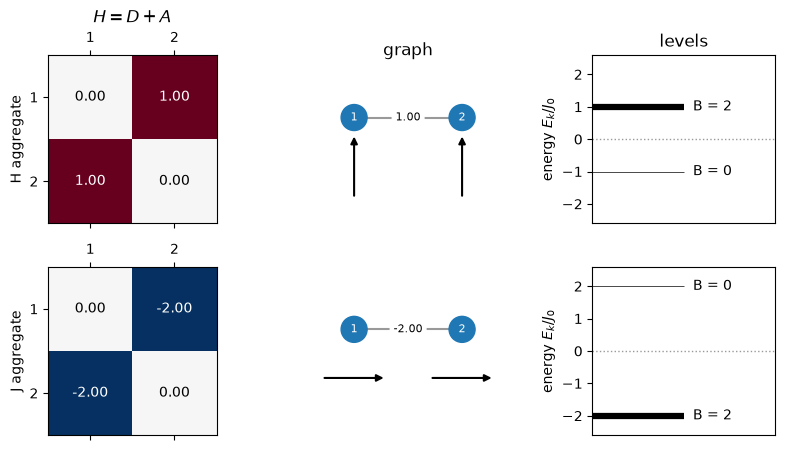

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(8, 4.6), gridspec_kw=dict(width_ratios=[1, 1.3, 1]))
for row, (name, d) in enumerate([("H aggregate", d_H), ("J aggregate", d_J)]):
    H = two_emitters(d)
    E, C, D, B = bright_states(H, d)
    draw_matrix(axs[row, 0], H, [1, 2])
    axs[row, 0].set_ylabel(name)
    draw_graph(axs[row, 1], H, {i: r[i, :2] for i in range(2)}, d, ["1", "2"])

    # energy levels: thick lines are bright, the dotted line is the energy of one emitter
    ax = axs[row, 2]
    for Ek, Bk in zip(E, B):
        ax.hlines(Ek, 0, 1, color="k", lw=0.5 + 2 * Bk)
        ax.text(1.1, Ek, f"B = {Bk:.0f}", va="center")
    ax.axhline(0, color="0.6", ls=":", lw=1)
    ax.set(xlim=(0, 2), ylim=(-2.6, 2.6), xticks=[], ylabel=r"energy $E_k/J_0$")
axs[0, 0].set_title(r"$H=D+A$"); axs[0, 1].set_title("graph"); axs[0, 2].set_title("levels")
plt.tight_layout(); plt.show()

The arrows below each node show the dipoles.

In both aggregates the bright state is the in-phase combination $|+\rangle$ with twice the brightness of one emitter, and the out-of-phase combination is dark.

Only its position changes, above the single-emitter energy (dotted line) for H and below it for J.

### From H to J: Kasha's picture

We tilt both dipoles by the same angle $\theta$ from the axis, $\mathbf d_m=d_0(\cos\theta,\sin\theta,0)$.

The coupling is $J=J_0(1-3\cos^2\theta)$, which changes sign at the magic angle $\theta_m=\arccos(1/\sqrt3)\approx54.7^\circ$.

We then twist the second dipole out of the plane by an angle $\chi$, $\mathbf d_1=d_0(0,1,0)$ and $\mathbf d_2=d_0(0,\cos\chi,\sin\chi)$.

Now $J=J_0\cos\chi$ and $B_\pm=1\pm\cos\chi$, so both states are partly bright (an oblique aggregate).

Lines are the numerics, open markers the analytic results.

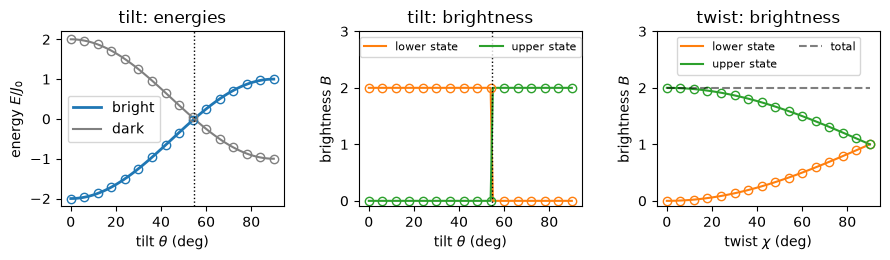

In [5]:
thetas, chis = np.linspace(0, 90, 91), np.linspace(0, 90, 91)
theta_m = np.degrees(np.arccos(1 / np.sqrt(3)))

# tilt both dipoles by theta
tilt = []
for th in np.radians(thetas):
    d = np.tile([np.cos(th), np.sin(th), 0], (2, 1))
    E, C, D, B = bright_states(two_emitters(d), d)
    tilt.append([E[np.argmax(B)], E[np.argmin(B)], B[0], B[1]])     # bright and dark energies, B of lower and upper
tilt = np.array(tilt)

# twist the second dipole by chi
twist = []
for ch in np.radians(chis):
    d = np.array([[0, 1, 0], [0, np.cos(ch), np.sin(ch)]])
    twist.append(bright_states(two_emitters(d), d)[3])               # B of lower and upper state
twist = np.array(twist)

fig, axs = plt.subplots(1, 3, figsize=(9, 2.7))
J_th = 1 - 3 * np.cos(np.radians(thetas)) ** 2
axs[0].plot(thetas, tilt[:, 0], color="C0", lw=2, label="bright")
axs[0].plot(thetas, tilt[:, 1], color="0.5", label="dark")
axs[0].plot(thetas[::6], J_th[::6], "o", mfc="none", color="C0")
axs[0].plot(thetas[::6], -J_th[::6], "o", mfc="none", color="0.5")
axs[0].set(xlabel=r"tilt $\theta$ (deg)", ylabel=r"energy $E/J_0$", title="tilt: energies")
axs[0].legend(loc="center left")

axs[1].plot(thetas, tilt[:, 2], color="C1", label="lower state")
axs[1].plot(thetas, tilt[:, 3], color="C2", label="upper state")
axs[1].plot(thetas[::6], 2 * (J_th[::6] < 0), "o", mfc="none", color="C1")
axs[1].plot(thetas[::6], 2 * (J_th[::6] > 0), "o", mfc="none", color="C2")
axs[1].set(xlabel=r"tilt $\theta$ (deg)", ylabel=r"brightness $B$", ylim=(-0.1, 3.0), title="tilt: brightness")
axs[1].legend(loc="upper center", ncol=2, fontsize=8)

axs[2].plot(chis, twist[:, 0], color="C1", label="lower state")
axs[2].plot(chis, twist[:, 1], color="C2", label="upper state")
axs[2].plot(chis[::6], 1 - np.cos(np.radians(chis[::6])), "o", mfc="none", color="C1")
axs[2].plot(chis[::6], 1 + np.cos(np.radians(chis[::6])), "o", mfc="none", color="C2")
# plot total brightness
axs[2].plot(chis, twist[:, 0] + twist[:, 1], color="k", ls="--", alpha=0.5, label="total")
axs[2].set(xlabel=r"twist $\chi$ (deg)", ylabel=r"brightness $B$", ylim=(-0.1, 3.0), title="twist: brightness")
axs[2].legend(loc="upper center", ncol=2, fontsize=8)

for ax in axs[:2]:
    ax.axvline(theta_m, color="k", ls=":", lw=1)
plt.tight_layout(); plt.show()

- **Tilt.** The bright state always has energy $+J$, so it moves from the bottom of the pair (J aggregate, small $\theta$) to the top (H aggregate, large $\theta$). The switch happens at the magic angle (dotted line), where $J=0$ and the two levels cross.
- **Twist.** Non-parallel dipoles never cancel completely, so the brightness is shared between the two states. The sum rule $B_++B_-=2$ holds at every angle.

## 3. A chain of $N$ emitters

$N$ identical emitters sit on the $x$ axis at spacing $a$, with open boundary conditions (the two ends have one neighbour only).

All dipoles are the same, $\mathbf d_m=\mathbf d$, tilted by $\theta$ from the chain axis.

We keep only nearest-neighbour couplings, so $A$ is tridiagonal with all off-diagonal entries equal to $J=J_0(1-3\cos^2\theta)$.

For this matrix the eigenstates are standing waves, like the modes of a string fixed at both ends,

$$c_m^{(k)}=\sqrt{\tfrac{2}{N+1}}\,\sin\frac{\pi km}{N+1},\qquad E_k=2J\cos\frac{\pi k}{N+1},\qquad k=1,\dots,N .$$

With identical dipoles $\mathbf D_k=\mathbf d\sum_mc_m^{(k)}$, so a state is bright only if its amplitudes do not average to zero.

The sum gives

$$B_k=\frac{2}{N+1}\cot^2\frac{\pi k}{2(N+1)}\ \text{ for odd }k,\qquad B_k=0\ \text{ for even }k .$$

Even $k$ are antisymmetric about the centre of the chain and are exactly dark.

### System

In [6]:
# system parameters
N = 10                                                # number of emitters
theta = 0.0                                           # dipole angle from the chain axis (deg): 0 = J aggregate, 90 = H aggregate
nn_only = True                                        # keep only nearest-neighbour couplings

def chain(N):
    # positions, dipoles and H = D + A of an open chain
    r = np.array([[m, 0.0, 0.0] for m in range(N)])                          # positions (units of a)
    d = np.tile([np.cos(np.radians(theta)), np.sin(np.radians(theta)), 0], (N, 1))   # identical dipoles
    eps = np.zeros(N)                                                        # site energies
    return r, d, np.diag(eps) + dipole_coupling(d, r, nn_only)

r, d, H = chain(N)
E, C, D, B = bright_states(H, d)

# analytic results for nearest-neighbour coupling J and identical dipoles
J = H[0, 1]
k = np.arange(1, N + 1)
E_an = 2 * J * np.cos(np.pi * k / (N + 1))
B_an = np.where(k % 2 == 1, 2 / (N + 1) / np.tan(np.pi * k / (2 * (N + 1))) ** 2, 0)

print(f"J = {J:.2f} J0")
print(f"sum_k B_k = {B.sum():.4f},  sum_m |d_m|^2/d0^2 = {np.sum(d ** 2) / d0 ** 2:.4f}")
print(f"brightest state: E = {E[np.argmax(B)]:.3f}, |D| = {np.linalg.norm(D[np.argmax(B)]):.3f}, B = {B.max():.3f}")

J = -2.00 J0
sum_k B_k = 10.0000,  sum_m |d_m|^2/d0^2 = 10.0000
brightest state: E = -3.838, |D| = 2.966, B = 8.795


### Graph

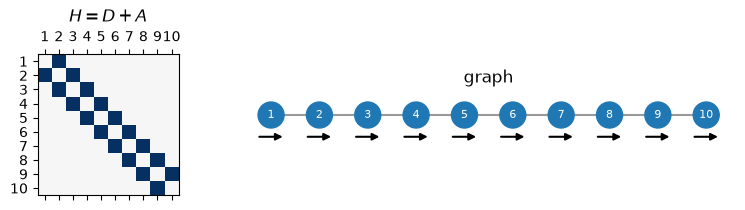

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(9, 2.6), gridspec_kw=dict(width_ratios=[1, 3.5]))
draw_matrix(axs[0], H, range(1, N + 1))
draw_graph(axs[1], H, {i: r[i, :2] for i in range(N)}, d, [str(i) for i in range(1, N + 1)])
axs[0].set_title(r"$H=D+A$"); axs[1].set_title("graph")
plt.show()

### Brightness of every state

Left: amplitudes of the three lowest states. Middle: brightness $B_k$ against energy $E_k$. Right: the brightness of the brightest state as the chain grows.

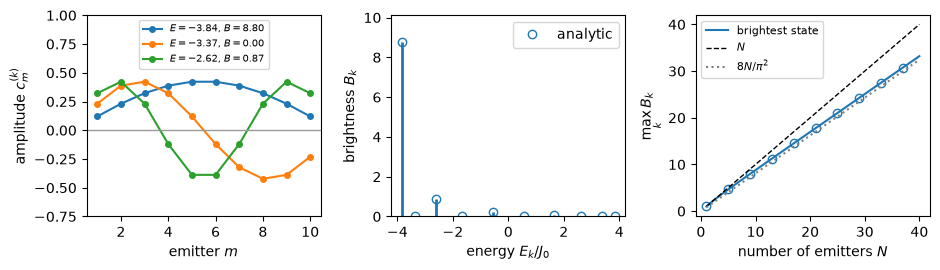

In [8]:
Ns = np.arange(1, 41)
B_max = [bright_states(chain(n)[2], chain(n)[1])[3].max() for n in Ns]
B_max_an = 2 / (Ns + 1) / np.tan(np.pi / (2 * (Ns + 1))) ** 2

fig, axs = plt.subplots(1, 3, figsize=(9.5, 2.8))

# amplitudes of the three lowest states, sign fixed so that the first emitter is positive
for kk in range(3):
    c = C[:, kk] * np.sign(C[0, kk])
    axs[0].plot(range(1, N + 1), c, "o-", ms=4, label=rf"$E={E[kk]:.2f}$, $B={B[kk]:.2f}$")
axs[0].axhline(0, color="0.6", lw=1)
axs[0].set(xlabel=r"emitter $m$", ylabel=r"amplitude $c_m^{(k)}$", ylim=(-0.75, 1.0))
axs[0].legend(fontsize=7, loc="upper center", ncol=1)

# brightness against energy
stems(axs[1], E, B, "C0")
axs[1].plot(E_an, B_an, "o", mfc="none", color="C0", label="analytic")
axs[1].set(xlabel=r"energy $E_k/J_0$", ylabel=r"brightness $B_k$", ylim=(0, 1.15 * B.max()))
axs[1].legend(loc="upper right")

# superradiance: the brightest state grows with N
axs[2].plot(Ns, B_max, color="C0", label="brightest state")
axs[2].plot(Ns[::4], B_max_an[::4], "o", mfc="none", color="C0")
axs[2].plot(Ns, Ns, "k--", lw=1, label=r"$N$")
axs[2].plot(Ns, 8 * Ns / np.pi ** 2, ":", color="0.5", label=r"$8N/\pi^2$")
axs[2].set(xlabel=r"number of emitters $N$", ylabel=r"$\max_k B_k$")
axs[2].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

- The lowest state of the J aggregate ($J<0$) has all amplitudes of the same sign, so all dipoles add in phase. It carries most of the brightness, about $8/\pi^2\approx81\%$ of the total for long chains.
- The states with even $k$ change sign about the centre of the chain and are dark. The other odd states are weakly bright.
- The brightest state grows linearly with $N$, which is superradiance. It stays below $N$ because the open ends make the amplitudes a half sine rather than uniform.
- With $\theta=90^\circ$ (H aggregate) the spectrum flips and the brightest state sits at the top of the band.

Exercise: change `theta`, set `nn_only = False`, or give the dipoles different orientations (for example alternating, `d[1::2] *= -1`), and see which states become bright. The analytic markers assume nearest neighbours, equal energies and identical dipoles.

## 4. Star: one cavity and $N$ emitters

A single cavity mode sits at the centre and couples to every emitter, and the emitters are not coupled to each other.

The cavity holds at most one photon, as everywhere in the single-excitation manifold. Following our convention the cavity is the first node, $|c\rangle=\hat a^\dagger|G\rangle$, followed by the emitters.

- Emitter $m$ couples to the cavity field through its dipole, $g_m=g\,(\mathbf d_m\cdot\hat{\mathbf e}_c)/d_0$, where $\hat{\mathbf e}_c$ is the polarisation of the cavity field and $g$ the coupling of a dipole $d_0$ aligned with it.
- The adjacency matrix has $A_{cm}=A_{mc}=g_m$ and no other entries. Energies are in units of $g$.
- The cavity has no free-space dipole, because its photon leaves through the mirrors (the leakage $\kappa$ of notebook 01), so its row in the dipole array is zero.

The cavity sees only the combination $\mathbf g=(g_1,\dots,g_N)$ of emitters. The analytic results for $\varepsilon=0$ are as follows.

- Two **polaritons** $(|c\rangle\pm|b\rangle)/\sqrt2$, with $|b\rangle=\sum_mg_m|m\rangle/\|\mathbf g\|$, at energies $E_\pm=\pm\|\mathbf g\|$. They have cavity weight $|c_c|^2=1/2$ and brightness $B_\pm=\|\sum_mg_m\mathbf d_m\|^2/(2\|\mathbf g\|^2d_0^2)$.
- $N-1$ **cavity-dark** states at $E=0$, orthogonal to $|b\rangle$, with no cavity weight. They carry the rest of the brightness, $\sum_m\|\mathbf d_m\|^2/d_0^2-2B_\pm$.

For identical dipoles along $\hat{\mathbf e}_c$ this gives $E_\pm=\pm g\sqrt N$, $B_\pm=N/2$, and states at $E=0$ that are dark both to the cavity and to free space.

### System

In [9]:
# system parameters
N = 6                                                 # number of emitters
g = 1.0                                               # cavity coupling of a dipole d0 along e_c (energy unit)
e_c = np.array([1.0, 0, 0])                           # cavity field polarisation
eps = np.zeros(N + 1)                                 # energies: cavity first, then emitters

d_same = np.tile([1.0, 0, 0], (N, 1))                 # identical dipoles along e_c
rng = np.random.default_rng(3)
d_rand = rng.normal(size=(N, 3))
d_rand *= d0 / np.linalg.norm(d_rand, axis=1)[:, None]    # random orientations, size d0

def star(d):
    # H = D + A with the cavity as node 0; dipole array with a zero row for the cavity
    gm = g * d @ e_c / d0
    A = np.zeros((N + 1, N + 1))
    A[0, 1:] = A[1:, 0] = gm
    return np.diag(eps) + A, np.vstack([np.zeros(3), d])

def star_analytic(d):
    # polariton energies and brightness, and total brightness of the cavity-dark states (eps = 0)
    gm = g * d @ e_c / d0
    G = np.linalg.norm(gm)
    B_pol = np.linalg.norm(gm @ d) ** 2 / (2 * G ** 2 * d0 ** 2)
    return np.array([-G, 0, G]), np.array([B_pol, np.sum(d ** 2) / d0 ** 2 - 2 * B_pol, B_pol])

for name, d in [("identical dipoles", d_same), ("random dipoles", d_rand)]:
    H, dips = star(d)
    E, C, D, B = bright_states(H, dips)
    print(name)
    print("  E_k       =", np.round(E, 3))
    print("  B_k       =", np.round(B, 3))
    print("  |c_c|^2   =", np.round(np.abs(C[0]) ** 2, 3))
    print(f"  sum rule: {B.sum():.4f} = {np.sum(d ** 2) / d0 ** 2:.4f}")

identical dipoles
  E_k       = [-2.449  0.     0.     0.     0.     0.     2.449]
  B_k       = [3. 0. 0. 0. 0. 0. 3.]
  |c_c|^2   = [0.5 0.  0.  0.  0.  0.  0.5]
  sum rule: 6.0000 = 6.0000
random dipoles
  E_k       = [-1.777  0.     0.     0.     0.     0.     1.777]
  B_k       = [1.724 1.862 0.69  0.    0.    0.    1.724]
  |c_c|^2   = [0.5 0.  0.  0.  0.  0.  0.5]
  sum rule: 6.0000 = 6.0000


### Graph and brightness

Left: the graph, with the emitter dipoles projected on the page. Middle: brightness $B_k$ against energy. Right: cavity weight $|c_c^{(k)}|^2$ against energy. Degenerate states are summed and their number is written on top.

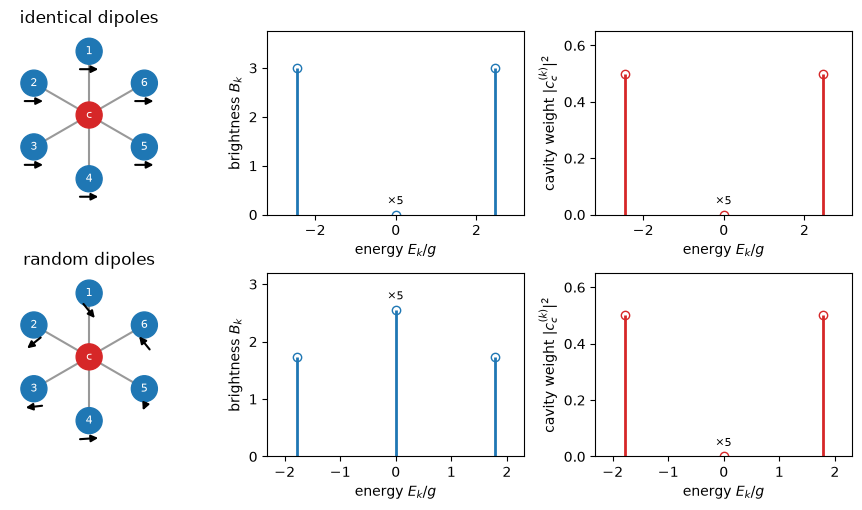

random dipoles, states at E = 0, B_k = [1.862 0.69  0.    0.    0.   ]


In [10]:
fig, axs = plt.subplots(2, 3, figsize=(9, 5.2), gridspec_kw=dict(width_ratios=[1, 1.2, 1.2]))
pos = {0: (0.0, 0.0)} | {m + 1: (1.6 * np.cos(t), 1.6 * np.sin(t))
                         for m, t in enumerate(np.linspace(0, 2 * np.pi, N, endpoint=False) + np.pi / 2)}
                         
for row, (name, d) in enumerate([("identical dipoles", d_same), ("random dipoles", d_rand)]):
    H, dips = star(d)
    E, C, D, B = bright_states(H, dips)
    E_an, B_an = star_analytic(d)

    draw_graph(axs[row, 0], H, pos, dips, ["c"] + [str(m) for m in range(1, N + 1)], ncav=1)
    axs[row, 0].set_title(name)

    stems(axs[row, 1], E, B, PART)
    axs[row, 1].plot(E_an, B_an, "o", mfc="none", color=PART)
    axs[row, 1].set(ylabel=r"brightness $B_k$", ylim=(0, 1.25 * max(B_an.max(), 1e-3)))

    stems(axs[row, 2], E, np.abs(C[0]) ** 2, CAV)
    axs[row, 2].plot(E_an, [0.5, 0, 0.5], "o", mfc="none", color=CAV)
    axs[row, 2].set(ylabel=r"cavity weight $|c_c^{(k)}|^2$", ylim=(0, 0.65))
    for ax in axs[row, 1:]:
        ax.set_xlabel(r"energy $E_k/g$"); ax.margins(x=0.15)
plt.tight_layout(); plt.show()

# with random dipoles the states at E = 0 are dark to the cavity, but not to free space
H, dips = star(d_rand)
E, C, D, B = bright_states(H, dips)
print("random dipoles, states at E = 0, B_k =", np.round(B[np.abs(E) < 1e-8], 3))

- **Identical dipoles.** The two polaritons share all the brightness, $B_\pm=N/2$, and the $N-1$ states at $E=0$ are dark to the cavity and to free space at the same time. The cavity sees exactly the same combination of emitters as free space does.
- **Random dipoles.** The couplings $g_m$ now differ in size and sign. The states at $E=0$ still have no cavity weight, but their dipoles no longer cancel, so they are bright in free space and take brightness away from the polaritons. At most two of them are bright, because being orthogonal to $\mathbf g$ means that their dipole has no component along $\hat{\mathbf e}_c$.

Being dark to the cavity means being orthogonal to $\mathbf g$, the projections of the dipoles on one polarisation. Being dark in free space means that the full 3D dipoles cancel. The two conditions agree only when all dipoles are parallel to the cavity field.

## 5. Take-home

* The brightness of a single-excitation state is $B_k=\|\sum_mc_m^{(k)}\mathbf d_m\|^2/d_0^2$, the size of its collective dipole relative to one emitter. It follows from the eigenvectors of $H=D+A$ and the local dipoles.
* Coupling moves brightness between states but does not create it, $\sum_kB_k=\sum_m\|\mathbf d_m\|^2/d_0^2$.
* For two parallel dipoles the in-phase state is bright and the out-of-phase state dark. The geometry sets the sign of $J$ and puts the bright state at the top (H aggregate) or at the bottom (J aggregate).
* In a chain the brightness concentrates in one state and grows with $N$ (superradiance). States antisymmetric about the centre are dark.
* In the star the cavity selects one collective state, which forms the polaritons with it. Whether the remaining states are also dark in free space depends on the orientation of the dipoles.